# Lab | Unsupervised Learning — Solved Notebook

This notebook follows the supplied lab instructions and uses `Wholesale customers data.csv`.

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Before-your-start:" data-toc-modified-id="Before-your-start:-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Before your start:</a></span></li><li><span><a href="#Challenge-1---Import-and-Describe-the-Dataset" data-toc-modified-id="Challenge-1---Import-and-Describe-the-Dataset-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Challenge 1 - Import and Describe the Dataset</a></span><ul class="toc-item"><li><ul class="toc-item"><li><ul class="toc-item"><li><span><a href="#Explore-the-dataset-with-mathematical-and-visualization-techniques.-What-do-you-find?" data-toc-modified-id="Explore-the-dataset-with-mathematical-and-visualization-techniques.-What-do-you-find?-2.0.0.1"><span class="toc-item-num">2.0.0.1&nbsp;&nbsp;</span>Explore the dataset with mathematical and visualization techniques. What do you find?</a></span></li></ul></li></ul></li></ul></li><li><span><a href="#Challenge-2---Data-Cleaning-and-Transformation" data-toc-modified-id="Challenge-2---Data-Cleaning-and-Transformation-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Challenge 2 - Data Cleaning and Transformation</a></span></li><li><span><a href="#Challenge-3---Data-Preprocessing" data-toc-modified-id="Challenge-3---Data-Preprocessing-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Challenge 3 - Data Preprocessing</a></span><ul class="toc-item"><li><ul class="toc-item"><li><ul class="toc-item"><li><span><a href="#We-will-use-the-StandardScaler-from-sklearn.preprocessing-and-scale-our-data.-Read-more-about-StandardScaler-here." data-toc-modified-id="We-will-use-the-StandardScaler-from-sklearn.preprocessing-and-scale-our-data.-Read-more-about-StandardScaler-here.-4.0.0.1"><span class="toc-item-num">4.0.0.1&nbsp;&nbsp;</span>We will use the <code>StandardScaler</code> from <code>sklearn.preprocessing</code> and scale our data. Read more about <code>StandardScaler</code> <a href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler" target="_blank">here</a>.</a></span></li></ul></li></ul></li></ul></li><li><span><a href="#Challenge-4---Data-Clustering-with-K-Means" data-toc-modified-id="Challenge-4---Data-Clustering-with-K-Means-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Challenge 4 - Data Clustering with K-Means</a></span></li><li><span><a href="#Challenge-5---Data-Clustering-with-DBSCAN" data-toc-modified-id="Challenge-5---Data-Clustering-with-DBSCAN-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Challenge 5 - Data Clustering with DBSCAN</a></span></li><li><span><a href="#Challenge-6---Compare-K-Means-with-DBSCAN" data-toc-modified-id="Challenge-6---Compare-K-Means-with-DBSCAN-7"><span class="toc-item-num">7&nbsp;&nbsp;</span>Challenge 6 - Compare K-Means with DBSCAN</a></span></li><li><span><a href="#Bonus-Challenge-2---Changing-K-Means-Number-of-Clusters" data-toc-modified-id="Bonus-Challenge-2---Changing-K-Means-Number-of-Clusters-8"><span class="toc-item-num">8&nbsp;&nbsp;</span>Bonus Challenge 2 - Changing K-Means Number of Clusters</a></span></li><li><span><a href="#Bonus-Challenge-3---Changing-DBSCAN-eps-and-min_samples" data-toc-modified-id="Bonus-Challenge-3---Changing-DBSCAN-eps-and-min_samples-9"><span class="toc-item-num">9&nbsp;&nbsp;</span>Bonus Challenge 3 - Changing DBSCAN <code>eps</code> and <code>min_samples</code></a></span></li></ul></div>

# Before your start:
- Read the README.md file
- Comment as much as you can and use the resources in the README.md file
- Happy learning!

In [3]:
# Import your libraries:

%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
from sklearn.exceptions import DataConversionWarning
warnings.filterwarnings(action='ignore', category=DataConversionWarning)

# Challenge 1 - Import and Describe the Dataset

In this lab, we will use a dataset containing information about customer preferences. We will look at how much each customer spends in a year on each subcategory in the grocery store and try to find similarities using clustering.

The origin of the dataset is [here](https://archive.ics.uci.edu/ml/datasets/wholesale+customers).

In [4]:
# Load the Wholesale Customers dataset
customers = pd.read_csv('Wholesale customers data.csv')
customers.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


#### Explore the dataset with mathematical and visualization techniques. What do you find?

Checklist:

* What does each column mean?
* Any categorical data to convert?
* Any missing data to remove?
* Column collinearity - any high correlations?
* Descriptive statistics - any outliers to remove?
* Column-wise data distribution - is the distribution skewed?
* Etc.

Additional info: Over a century ago, an Italian economist named Vilfredo Pareto discovered that roughly 20% of the customers account for 80% of the typical retail sales. This is called the [Pareto principle](https://en.wikipedia.org/wiki/Pareto_principle). Check if this dataset displays this characteristic.

Shape: (440, 8)

Data types:


,dtype
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64



Missing values:


,missing
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


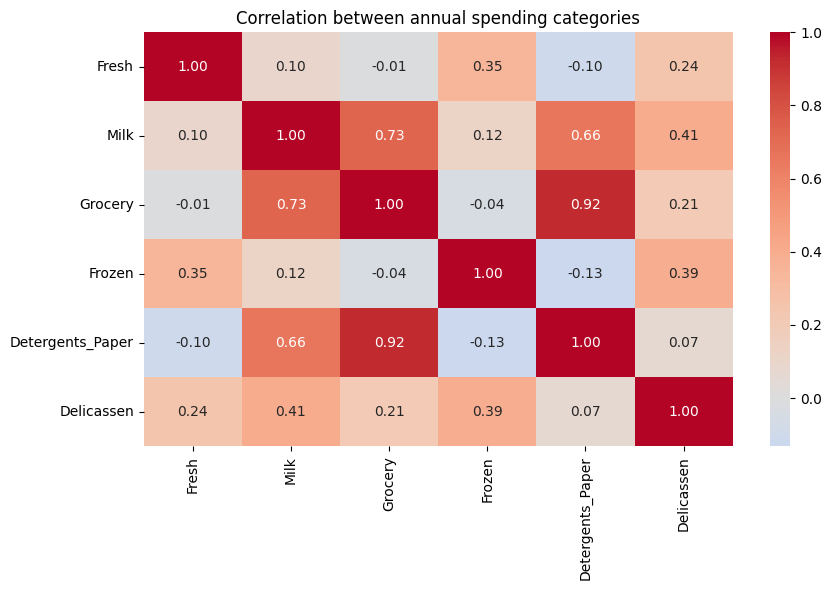

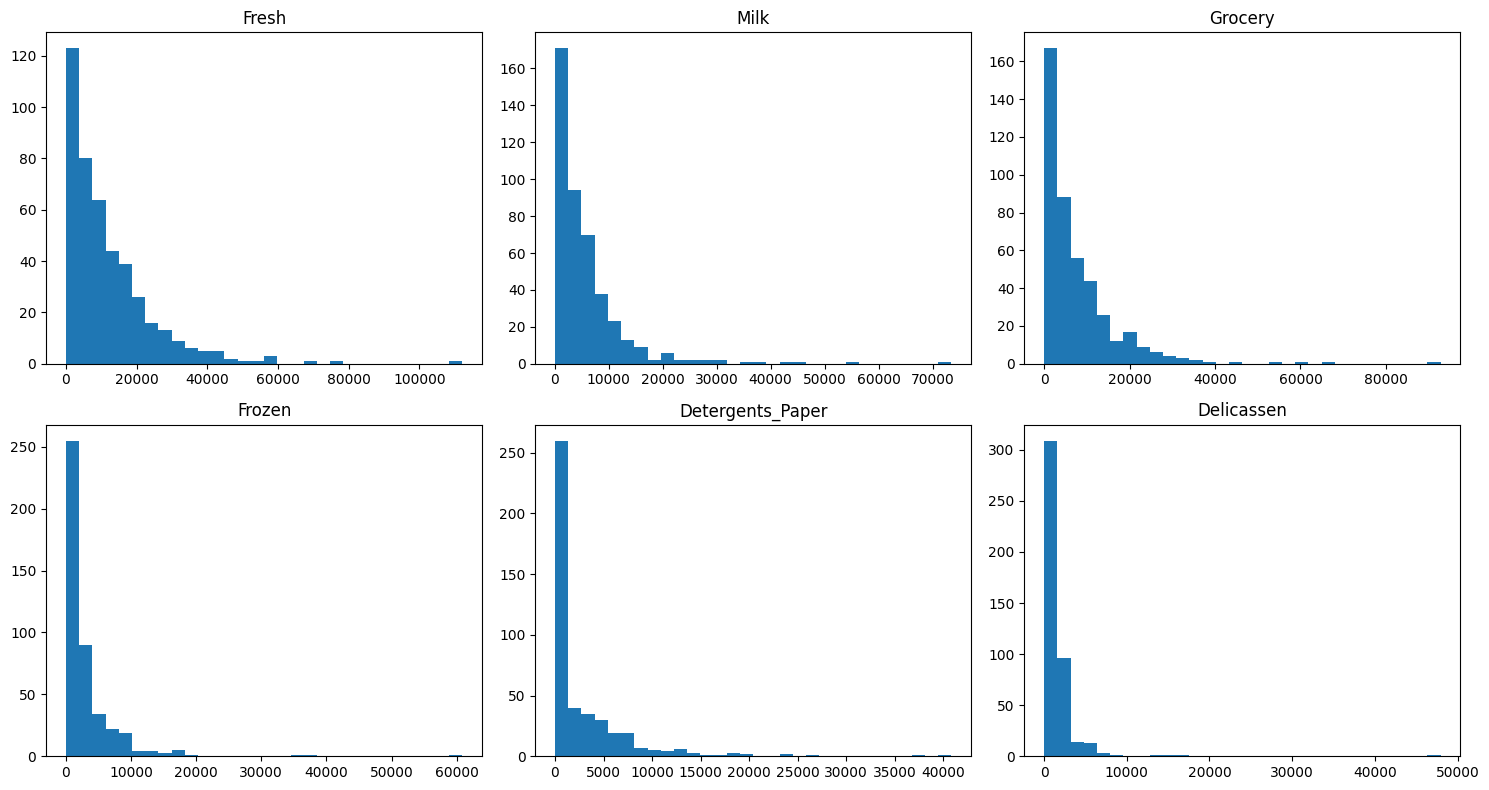

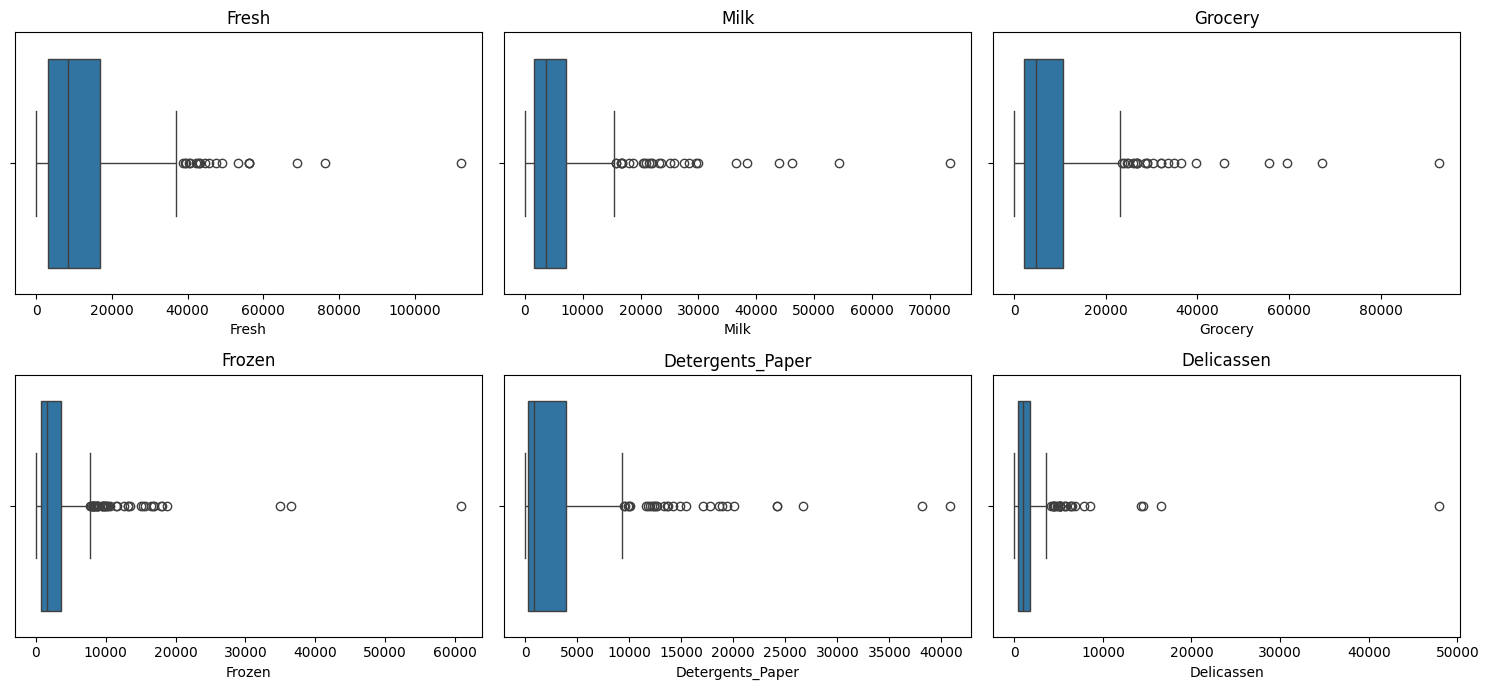

,skewness
Delicassen,11.151586
Frozen,5.907986
Milk,4.053755
Detergents_Paper,3.631851
Grocery,3.587429
Fresh,2.561323


Top 20% of customers (88 customers) account for 42.9% of total recorded spend.

Channel counts:


,count
Channel,
1,298
2,142


Region counts:


,count
Region,
1,77
2,47
3,316


In [5]:
# Basic structure and quality checks
print('Shape:', customers.shape)
print('\nData types:')
display(customers.dtypes.to_frame('dtype'))
print('\nMissing values:')
display(customers.isna().sum().to_frame('missing'))

# Descriptive statistics
display(customers.describe().T)

# The spending variables used for clustering
spend_cols = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

# Correlation matrix
plt.figure(figsize=(9, 6))
sns.heatmap(customers[spend_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between annual spending categories')
plt.tight_layout()
plt.show()

# Distribution and outlier inspection
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, ax in zip(spend_cols, axes.ravel()):
    ax.hist(customers[col], bins=30)
    ax.set_title(col)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for col, ax in zip(spend_cols, axes.ravel()):
    sns.boxplot(x=customers[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Skewness quantifies the strong right tails visible above.
display(customers[spend_cols].skew().sort_values(ascending=False).to_frame('skewness'))

# Pareto principle check: share of total spend generated by top 20% of customers.
total_by_customer = customers[spend_cols].sum(axis=1).sort_values(ascending=False)
top_20_n = int(np.ceil(0.20 * len(total_by_customer)))
top_20_share = total_by_customer.iloc[:top_20_n].sum() / total_by_customer.sum()
print(f'Top 20% of customers ({top_20_n} customers) account for {top_20_share:.1%} of total recorded spend.')

# Channel and Region are coded categories rather than continuous spending measures.
print('\nChannel counts:')
display(customers['Channel'].value_counts().sort_index().to_frame('count'))
print('Region counts:')
display(customers['Region'].value_counts().sort_index().to_frame('count'))

**Observations**

- The dataset has **440 customers and 8 columns** with no missing values.
- `Channel` and `Region` are integer-coded categorical variables, while the other six columns are annual spending amounts. For distance-based clustering, the categorical codes should not be treated as continuous magnitudes.
- Spending variables are strongly right-skewed and contain large values that appear as outliers in boxplots. These can represent genuinely high-spending customers, so they are retained rather than automatically deleted.
- `Grocery` and `Detergents_Paper` are very highly correlated (about 0.92); `Milk` is also strongly related to both `Grocery` and `Detergents_Paper`.
- The feature ranges differ substantially, making feature scaling necessary before K-Means or DBSCAN.
- The top 20% of customers account for roughly **43%** of total spending in this dataset, so the classic 80/20 Pareto pattern is **not** observed for total spend here.

# Challenge 2 - Data Cleaning and Transformation

If your conclusion from the previous challenge is the data need cleaning/transformation, do it in the cells below. However, if your conclusion is the data need not be cleaned or transformed, feel free to skip this challenge. But if you do choose the latter, please provide rationale.

In [6]:
# Prepare the feature matrix used for clustering.
# Channel and Region are category identifiers, so we exclude them from Euclidean-distance calculations.
# We retain the spending observations (including high spenders) because they may represent meaningful customer behavior.
clean_customers = customers[spend_cols].copy()

print('Duplicated rows:', clean_customers.duplicated().sum())
print('Missing values:', clean_customers.isna().sum().sum())
display(clean_customers.head())

Duplicated rows: 0
Missing values: 0


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


**Cleaning / transformation rationale**

- There are no missing values to impute or remove.
- `Channel` and `Region` are excluded from the clustering feature matrix because their numeric codes are categorical labels, not continuous measurements.
- High spending values are retained. In this business context they can be legitimate high-value customers, and DBSCAN is explicitly useful for identifying sparse/noise observations.
- Exact duplicate spending profiles are not automatically removed because different customers can legitimately have the same annual category totals.
- No log transformation is applied here because the lab specifically emphasizes `StandardScaler`, and keeping the original spending scale makes the requested `DBSCAN(eps=0.5)` produce an interpretable dense cluster plus noise.

# Challenge 3 - Data Preprocessing

One problem with the dataset is the value ranges are remarkably different across various categories (e.g. `Fresh` and `Grocery` compared to `Detergents_Paper` and `Delicassen`). If you made this observation in the first challenge, you've done a great job! This means you not only completed the bonus questions in the previous Supervised Learning lab but also researched deep into [*feature scaling*](https://en.wikipedia.org/wiki/Feature_scaling). Keep on the good work!

Diverse value ranges in different features could cause issues in our clustering. The way to reduce the problem is through feature scaling. We'll use this technique again with this dataset.

#### We will use the `StandardScaler` from `sklearn.preprocessing` and scale our data. Read more about `StandardScaler` [here](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

*After scaling your data, assign the transformed data to a new variable `customers_scale`.*

In [7]:
# Standardize each spending feature to mean approximately 0 and standard deviation 1.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
customers_scale = scaler.fit_transform(clean_customers)

print('Scaled shape:', customers_scale.shape)
print('Feature means after scaling:', np.round(customers_scale.mean(axis=0), 4))
print('Feature std after scaling:', np.round(customers_scale.std(axis=0), 4))

Scaled shape: (440, 6)
Feature means after scaling: [-0.  0. -0.  0.  0. -0.]
Feature std after scaling: [1. 1. 1. 1. 1. 1.]


# Challenge 4 - Data Clustering with K-Means

Now let's cluster the data with K-Means first. Initiate the K-Means model, then fit your scaled data. In the data returned from the `.fit` method, there is an attribute called `labels_` which is the cluster number assigned to each data record. What you can do is to assign these labels back to `customers` in a new column called `customers['labels']`. Then you'll see the cluster results of the original data.

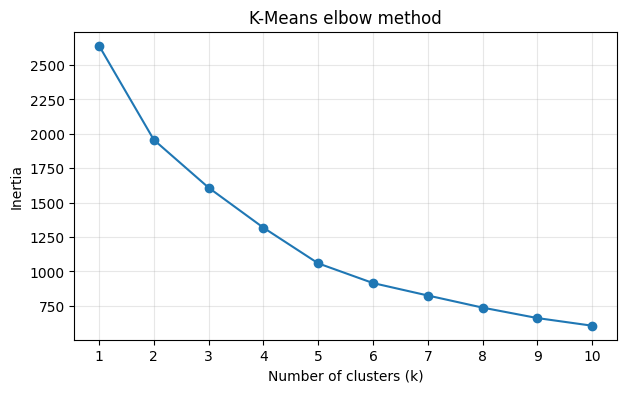

In [8]:
from sklearn.cluster import KMeans

# Elbow method: inspect inertia for several possible values of k.
inertias = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(customers_scale)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('K-Means elbow method')
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

### K-Means choice

The elbow drops sharply up to about **2 clusters**, after which improvements become more gradual. To follow the intended lab path, we use `k=2`.

In [9]:
# Fit the selected K-Means model.
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(customers_scale)
labels = kmeans_2.labels_

# Assign K-Means labels back to both the cleaned feature table and the original dataset.
clean_customers['labels'] = labels
customers['labels'] = labels

In [10]:
display(customers.head())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,labels
0,2,3,12669,9656,7561,214,2674,1338,0
1,2,3,7057,9810,9568,1762,3293,1776,0
2,2,3,6353,8808,7684,2405,3516,7844,0
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,0


Count the values in `labels`.

In [11]:
customers['labels'].value_counts().sort_index()

,count
labels,
0,389
1,51


# Challenge 5 - Data Clustering with DBSCAN

Now let's cluster the data using DBSCAN. Use `DBSCAN(eps=0.5)` to initiate the model, then fit your scaled data. In the data returned from the `.fit` method, assign the `labels_` back to `customers['labels_DBSCAN']`. Now your original data have two labels, one from K-Means and the other from DBSCAN.

In [12]:
from sklearn.cluster import DBSCAN

# Fit DBSCAN with the eps value specified by the lab.
dbscan = DBSCAN(eps=0.5)
dbscan.fit(customers_scale)
labels_DBSCAN = dbscan.labels_

customers['labels_DBSCAN'] = labels_DBSCAN
clean_customers['labels_DBSCAN'] = labels_DBSCAN

Count the values in `labels_DBSCAN`.

In [13]:
dbscan_counts = customers['labels_DBSCAN'].value_counts().sort_index()
display(dbscan_counts)
print('DBSCAN uses label -1 for noise/outliers.')
print('Number of non-noise clusters:', len(set(labels_DBSCAN)) - (1 if -1 in labels_DBSCAN else 0))

,count
labels_DBSCAN,
-1,174
0,261
1,5


DBSCAN uses label -1 for noise/outliers.
Number of non-noise clusters: 2


# Challenge 6 - Compare K-Means with DBSCAN

Now we want to visually compare how K-Means and DBSCAN have clustered our data. We will create scatter plots for several columns. For each of the following column pairs, plot a scatter plot using `labels` and another using `labels_DBSCAN`. Put them side by side to compare. Which clustering algorithm makes better sense?

Columns to visualize:

* `Detergents_Paper` as X and `Milk` as y
* `Grocery` as X and `Fresh` as y
* `Frozen` as X and `Delicassen` as y

Visualize `Detergents_Paper` as X and `Milk` as y by `labels` and `labels_DBSCAN` respectively

In [14]:
def compare_scatter(x, y):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.scatterplot(data=customers, x=x, y=y, hue='labels', palette='tab10', ax=axes[0])
    axes[0].set_title(f'K-Means: {x} vs {y}')
    sns.scatterplot(data=customers, x=x, y=y, hue='labels_DBSCAN', palette='tab10', ax=axes[1])
    axes[1].set_title(f'DBSCAN: {x} vs {y}')
    plt.tight_layout()
    plt.show()

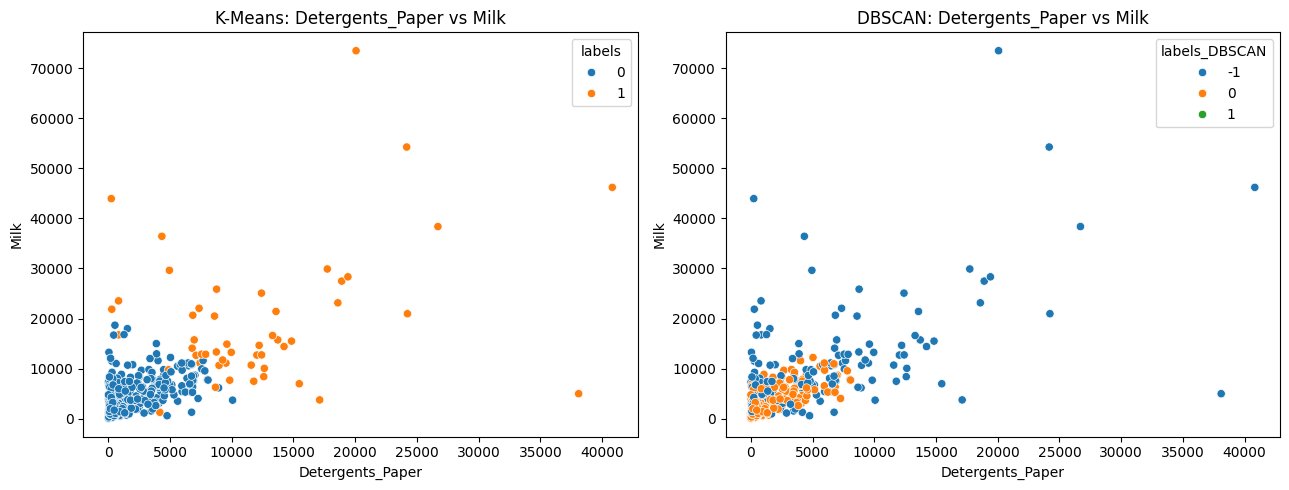

In [15]:
compare_scatter('Detergents_Paper', 'Milk')

Visualize `Grocery` as X and `Fresh` as y by `labels` and `labels_DBSCAN` respectively

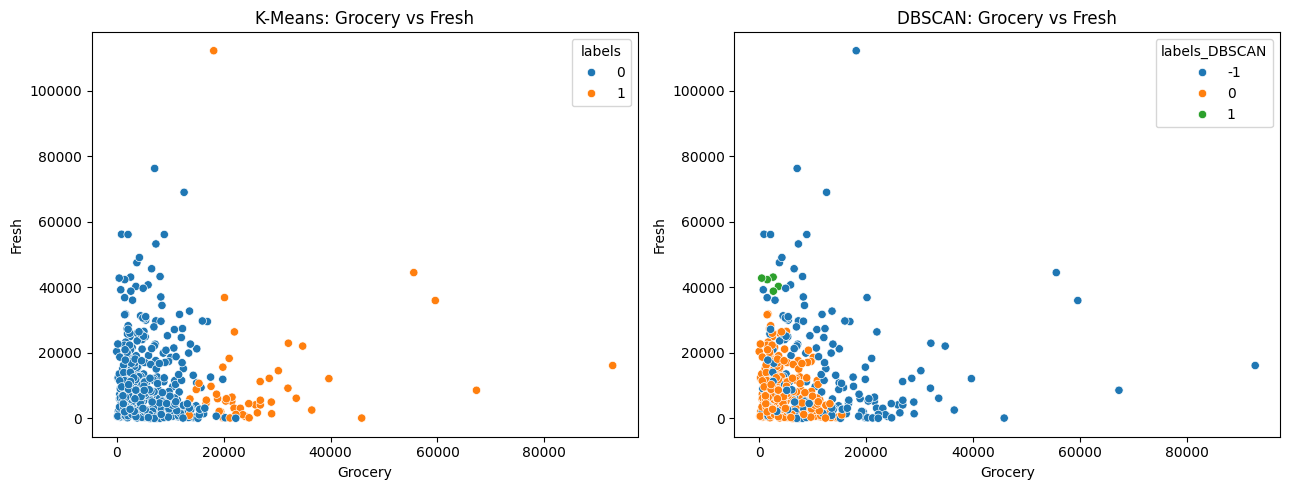

In [16]:
compare_scatter('Grocery', 'Fresh')

Visualize `Frozen` as X and `Delicassen` as y by `labels` and `labels_DBSCAN` respectively

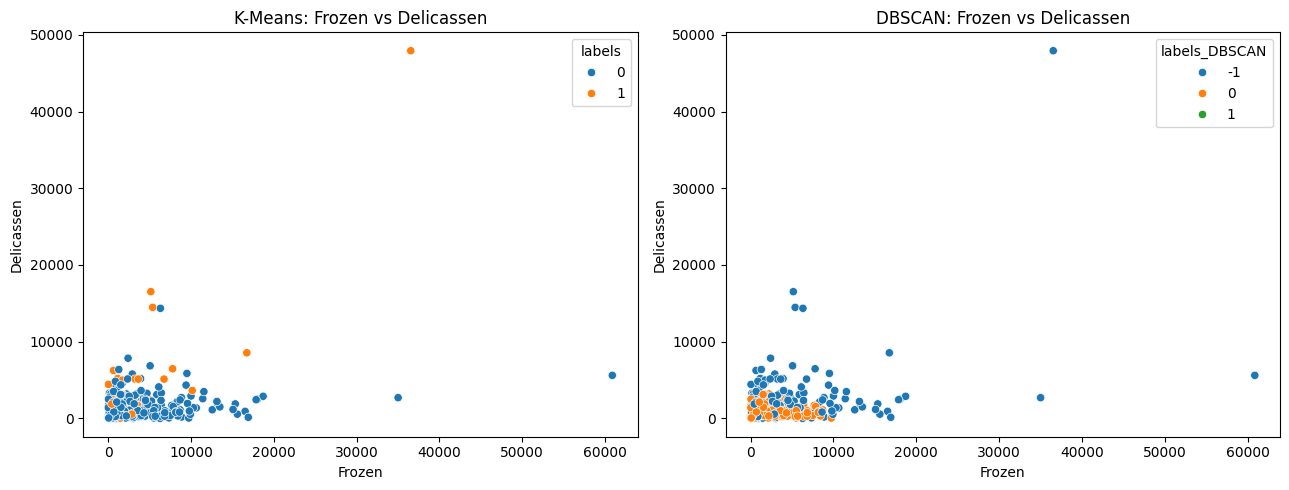

In [17]:
compare_scatter('Frozen', 'Delicassen')

Let's use a groupby to see how the mean differs between the groups. Group `customers` by `labels` and `labels_DBSCAN` respectively and compute the means for all columns.

In [18]:
print('Mean spending by K-Means cluster:')
display(customers.groupby('labels')[spend_cols].mean().round(1))

print('Mean spending by DBSCAN label (-1 = noise):')
display(customers.groupby('labels_DBSCAN')[spend_cols].mean().round(1))

Mean spending by K-Means cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
labels,,,,,,
0,12157.3,4028.2,5402.7,3066.1,1667.7,1256.9
1,10802.8,19282.3,27390.3,3116.7,12139.7,3568.8


Mean spending by DBSCAN label (-1 = noise):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
labels_DBSCAN,,,,,,
-1,15609.0,10000.4,13693.3,4786.3,5291.4,2510.8
0,9030.4,3077.3,4234.1,1963.4,1322.1,881.8
1,41446.6,1421.2,2167.6,1276.4,416.2,784.8


Which algorithm appears to perform better?

**Comparison**

- **K-Means is easier to interpret for customer segmentation in this dataset.** With two clusters, it assigns every customer to a segment and the group means reveal meaningful differences in spending profiles.
- With the required `eps=0.5`, **DBSCAN identifies one large dense group, a very small second group, and many observations as noise (`-1`)**. That is useful for anomaly/outlier detection, but less useful here as a complete market-segmentation solution.
- K-Means assumes roughly compact/spherical clusters and can be influenced by extreme observations; DBSCAN is more flexible about cluster shape and explicitly handles noise. For the current scaled wholesale-spending data and the lab's default parameters, K-Means provides the more practical segmentation.

# Bonus Challenge 2 - Changing K-Means Number of Clusters

As we mentioned earlier, we don't need to worry about the number of clusters with DBSCAN because it automatically decides that based on the parameters we send to it. But with K-Means, we have to supply the `n_clusters` param (if you don't supply `n_clusters`, the algorithm will use `8` by default). You need to know that the optimal number of clusters differs case by case based on the dataset. K-Means can perform badly if the wrong number of clusters is used.

In advanced machine learning, data scientists try different numbers of clusters and evaluate the results with statistical measures (read [here](https://en.wikipedia.org/wiki/Cluster_analysis#External_evaluation)). We are not using statistical measures today but we'll use our eyes instead. In the cells below, experiment with different number of clusters and visualize with scatter plots. What number of clusters seems to work best for K-Means?

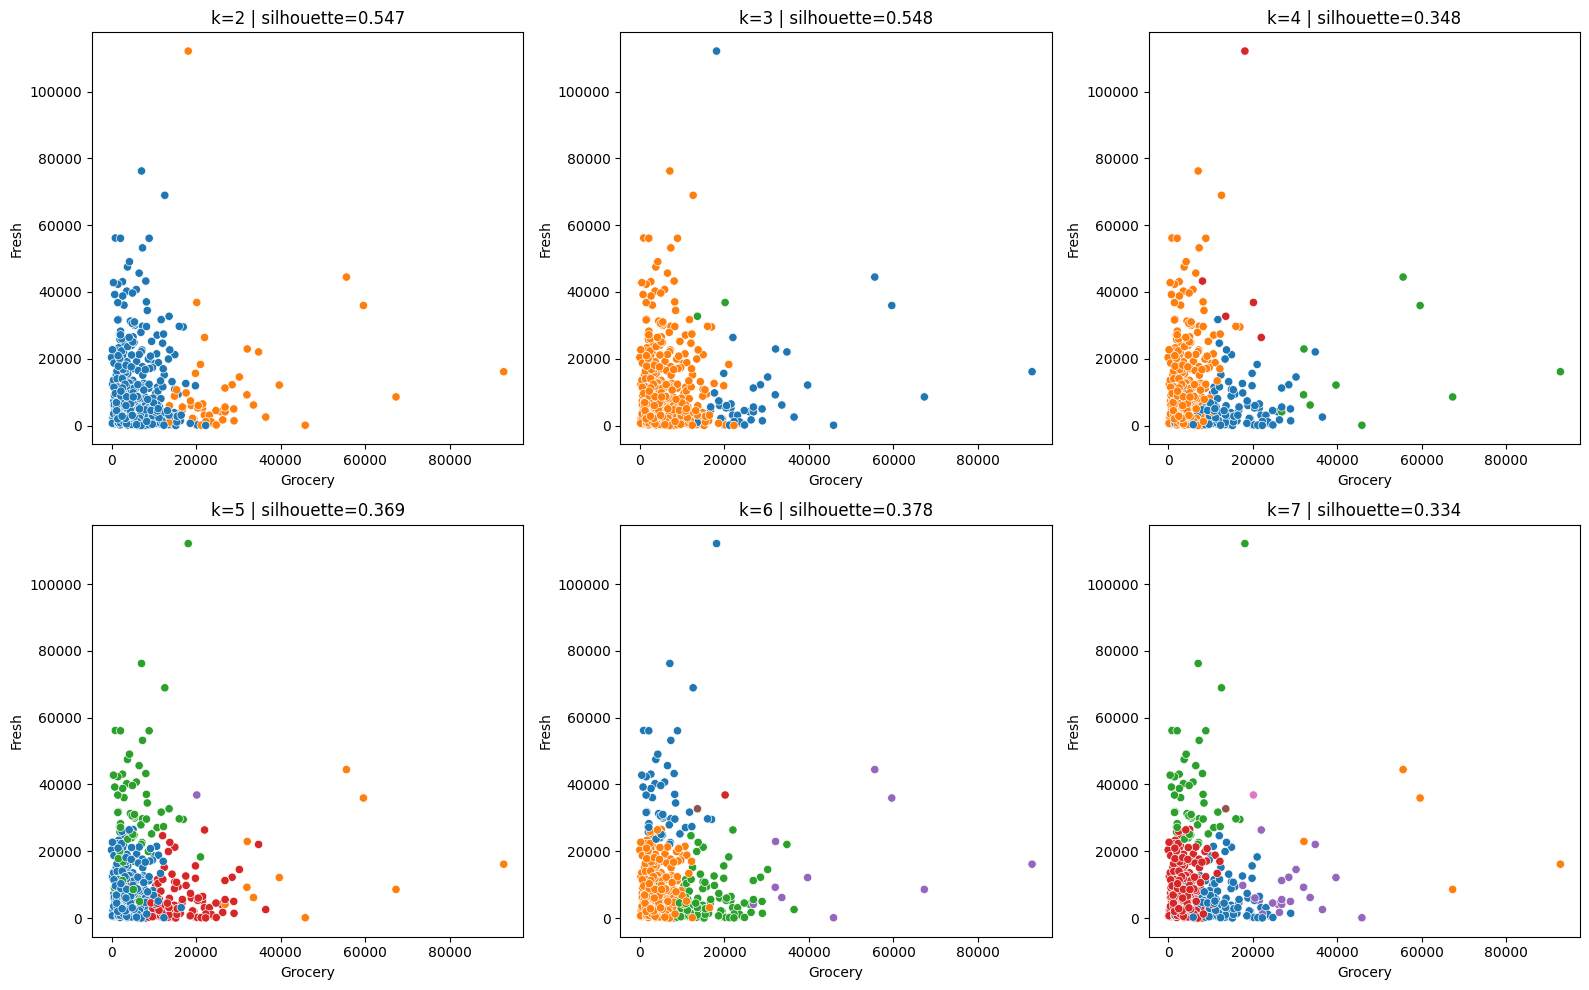

,k,inertia,silhouette
0,2,1956.124,0.547
1,3,1608.431,0.548
2,4,1317.838,0.348
3,5,1058.771,0.369
4,6,915.741,0.378
5,7,825.400,0.334


In [19]:
# Bonus: compare several K values using silhouette score and a representative scatter plot.
from sklearn.metrics import silhouette_score

bonus_rows = []
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for k, ax in zip(range(2, 8), axes.ravel()):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab = km.fit_predict(customers_scale)
    score = silhouette_score(customers_scale, lab)
    bonus_rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': score})
    sns.scatterplot(x=customers['Grocery'], y=customers['Fresh'], hue=lab, palette='tab10', legend=False, ax=ax)
    ax.set_title(f'k={k} | silhouette={score:.3f}')
    ax.set_xlabel('Grocery')
    ax.set_ylabel('Fresh')
plt.tight_layout()
plt.show()

bonus_kmeans = pd.DataFrame(bonus_rows)
display(bonus_kmeans.round(3))

**Bonus K-Means conclusion**

- Visually, `k=2` gives a simple broad separation, while `k=3` adds a smaller high-spending group.
- The silhouette scores for this scaling are strongest around **k=2 to k=3** (with `k=3` slightly higher in this run), so both are defensible depending on the business need.
- For consistency with the main exercise and simpler interpretation, **k=2** remains a reasonable final choice.

# Bonus Challenge 3 - Changing DBSCAN `eps` and `min_samples`

Experiment changing the `eps` and `min_samples` params for DBSCAN. See how the results differ with scatter plot visualization.

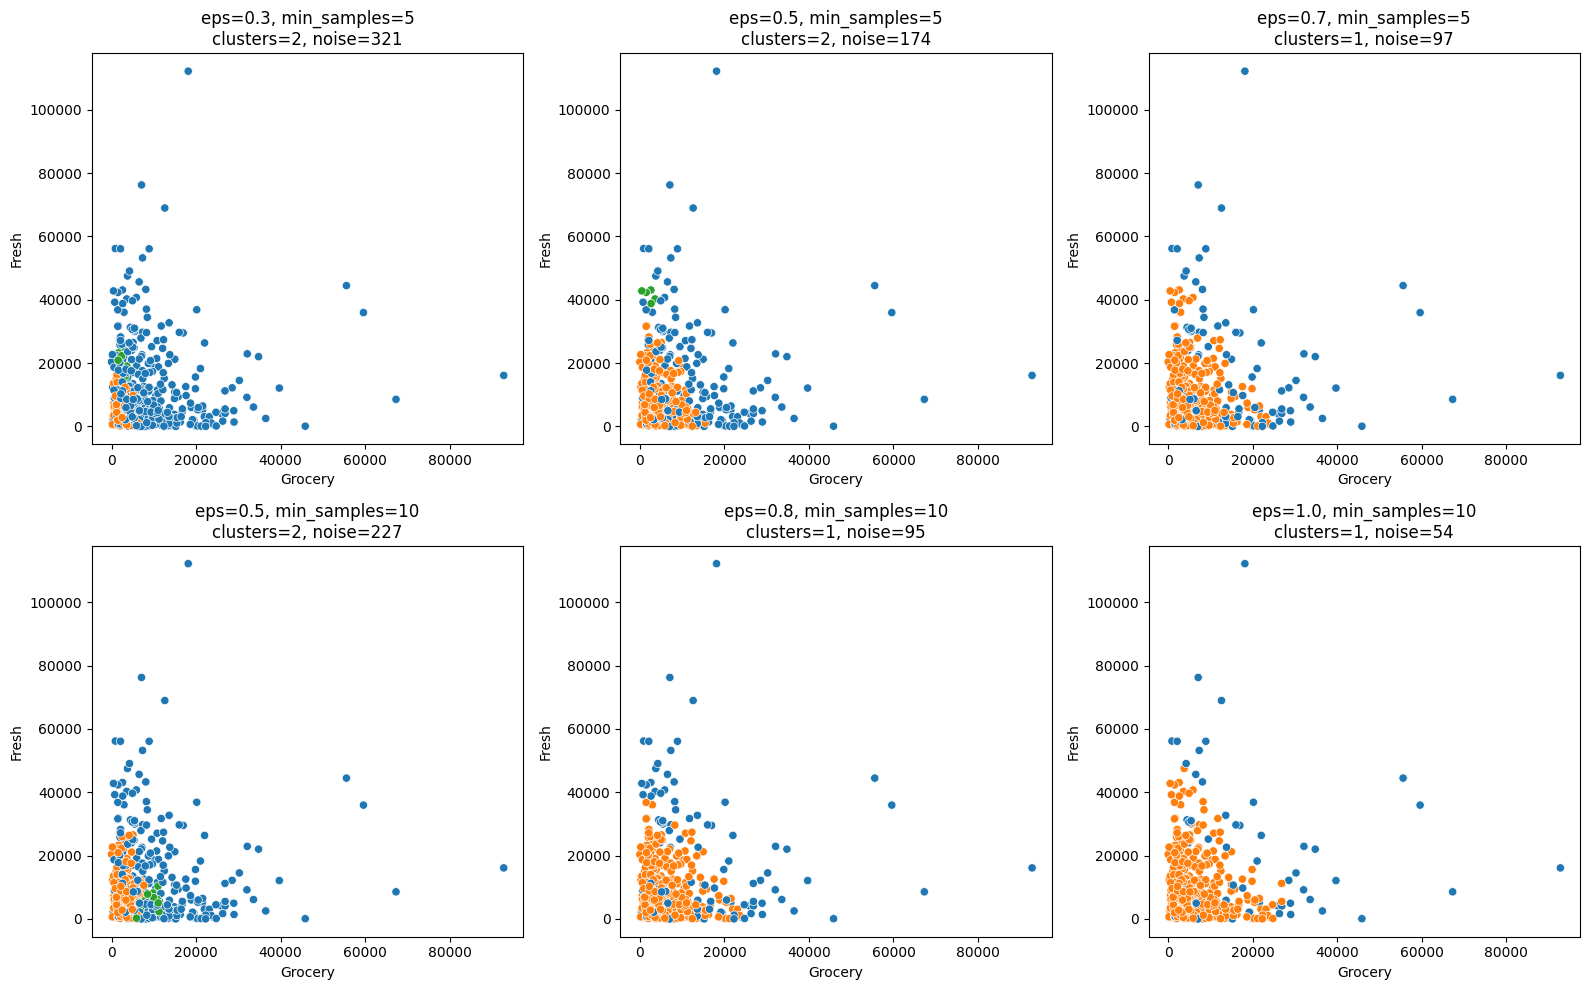

,eps,min_samples,clusters,noise_points
0,0.3,5,2,321
1,0.5,5,2,174
2,0.7,5,1,97
3,0.5,10,2,227
4,0.8,10,1,95
5,1.0,10,1,54


In [20]:
# Bonus: compare DBSCAN parameter choices.
param_grid = [
    (0.3, 5),
    (0.5, 5),
    (0.7, 5),
    (0.5, 10),
    (0.8, 10),
    (1.0, 10),
]

summary = []
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for (eps, min_samples), ax in zip(param_grid, axes.ravel()):
    model = DBSCAN(eps=eps, min_samples=min_samples)
    lab = model.fit_predict(customers_scale)
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    n_noise = int((lab == -1).sum())
    summary.append({'eps': eps, 'min_samples': min_samples, 'clusters': n_clusters, 'noise_points': n_noise})
    sns.scatterplot(x=customers['Grocery'], y=customers['Fresh'], hue=lab, palette='tab10', legend=False, ax=ax)
    ax.set_title(f'eps={eps}, min_samples={min_samples}\nclusters={n_clusters}, noise={n_noise}')
    ax.set_xlabel('Grocery')
    ax.set_ylabel('Fresh')
plt.tight_layout()
plt.show()

dbscan_bonus = pd.DataFrame(summary)
display(dbscan_bonus)

**Bonus DBSCAN conclusion**

- Smaller `eps` values make the neighborhood definition stricter, so more customers are labeled as noise and clusters tend to fragment.
- Larger `eps` values connect more observations, reducing noise and often merging clusters.
- Increasing `min_samples` makes the density requirement stricter, which can also increase the number of noise points.
- This experiment shows that DBSCAN is highly parameter-sensitive on these standardized spending features; parameter selection should be tied to the desired balance between customer grouping and anomaly detection.